# Setup and Import packages

In [1]:
! pip install numpy pandas matplotlib seaborn scikit-learn

# EDA Packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

# Machine Learning Packages
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Save Model
import pickle

# Warnings Filter
import warnings as w
w.filterwarnings('ignore')

# Time Stamp
import time as t
print(f'Last Update : {t.asctime()}')

Last Update : Sat Oct 24 15:33:33 2026


# Load Shoes Dataset

In [2]:
df = pd.read_csv('/kaggle/input/datasets/engraamirjamil/shoe-size-dataset/shoe_size_dataset.csv')
df.head()

,height_cm,weight_kg,gender,shoe_size_us
0,177.4,96.8,Male,10.0
1,167.7,56.8,Female,6.0
2,156.6,66.4,Female,4.0
3,154.1,78.5,Female,4.0
4,183.3,73.3,Male,9.5


# Exploratory Data Analysis (EDA)

In [3]:

print("Shape of dataset:", df.shape)


df.info()


print("\nColumn Names:", df.columns.tolist())

Shape of dataset: (500, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   height_cm     500 non-null    float64
 1   weight_kg     500 non-null    float64
 2   gender        500 non-null    object 
 3   shoe_size_us  500 non-null    float64
dtypes: float64(3), object(1)
memory usage: 15.8+ KB

Column Names: ['height_cm', 'weight_kg', 'gender', 'shoe_size_us']


In [4]:
# Missing values count check 
print("Missing values in each column:")
print(df.isnull().sum())

# Null values drop ya fill karo 
df.dropna(inplace=True)

# Duplicate rows count aud handling
print("\nDuplicate rows count:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Remaining duplicate rows count:", df.duplicated().sum())

Missing values in each column:
height_cm       0
weight_kg       0
gender          0
shoe_size_us    0
dtype: int64

Duplicate rows count: 0
Remaining duplicate rows count: 0


In [5]:
# Outliers handling using IQR Method for numerical columns
num_cols = ['height_cm', 'weight_kg', 'shoe_size_us']

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

print("Dataset shape after removing outliers:", df.shape)

Dataset shape after removing outliers: (499, 4)


In [6]:
# Numerical columns ki summary statistics
df.describe()

,height_cm,weight_kg,shoe_size_us
count,499.000000,499.000000,499.000000
mean,168.433667,70.050100,6.686373
std,8.571405,12.651545,2.034179
min,146.700000,35.900000,4.000000
25%,162.250000,61.100000,4.750000
50%,168.000000,68.900000,6.500000
75%,174.800000,78.650000,8.500000
max,191.800000,104.300000,11.000000


In [7]:
# Target feature (gender) count check 
target_col = 'gender' 
print(df[target_col].value_counts())

gender
Female    259
Male      240
Name: count, dtype: int64


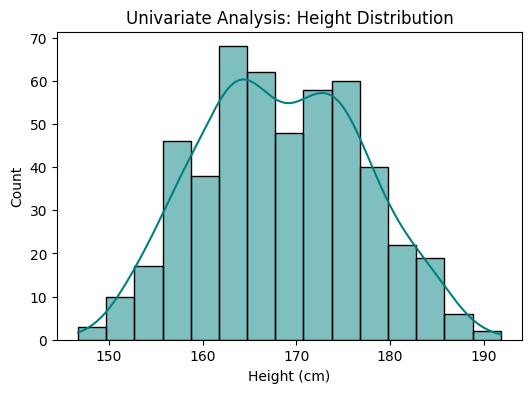

In [8]:
# Height distribution graph
plt.figure(figsize=(6, 4))
sns.histplot(df['height_cm'], kde=True, color='teal')
plt.title('Univariate Analysis: Height Distribution')
plt.xlabel('Height (cm)')
plt.show()

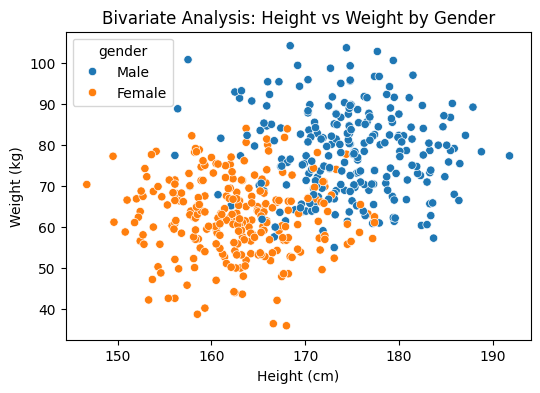

In [9]:
# Height vs Weight categorized by Gender
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='height_cm', y='weight_kg', hue=target_col)
plt.title('Bivariate Analysis: Height vs Weight by Gender')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.show()

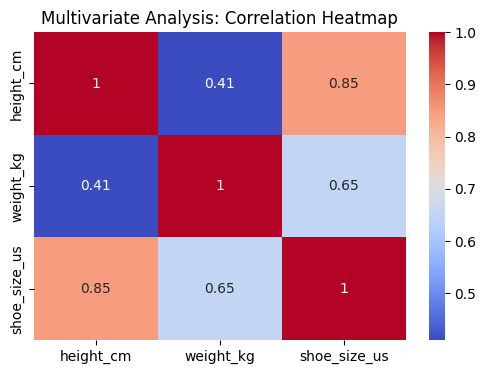

In [10]:
# Correlation Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Multivariate Analysis: Correlation Heatmap')
plt.show()

# Preprocessing for Machine Learning

In [11]:
# 1. Features (X) and  Target (y) 
X = df.drop(columns=[target_col])
y = df[target_col]

# 2. Target Variable (gender) ko encode  (Male -> 1, Female -> 0)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 3. Numerical Features scale 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features Shape:", X_scaled.shape)
print("Target Shape:", y_encoded.shape)

Features Shape: (499, 3)
Target Shape: (499,)


# Train Test Split

In [12]:
# 80% Train, 20% Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Training Data Shape: {X_train.shape}")
print(f"Testing Data Shape: {X_test.shape}")

Training Data Shape: (399, 3)
Testing Data Shape: (100, 3)


#  Model Training & Comparison (3 Models)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 3 Models initialize karo
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# Training loop
for name, model_obj in models.items():
    model_obj.fit(X_train, y_train)

print("All 3 Models Trained Successfully!")

All 3 Models Trained Successfully!


# Model Evaluation & Best Model Selection

In [14]:
results = {}

# Performance Evaluation
for name, model_obj in models.items():
    preds = model_obj.predict(X_test)
    acc = accuracy_score(y_test, preds)
    results[name] = acc
    
    print(f"================ {name} ================")
    print(f"Accuracy: {acc * 100:.2f}%")
    print(classification_report(y_test, preds, target_names=le.classes_))
    print("\n")

# Best Model Select karo
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

print(f"🏆 Best Performing Model: {best_model_name} with {results[best_model_name]*100:.2f}% Accuracy")

================ Logistic Regression ================
Accuracy: 95.00%
              precision    recall  f1-score   support

      Female       0.93      0.98      0.95        52
        Male       0.98      0.92      0.95        48

    accuracy                           0.95       100
   macro avg       0.95      0.95      0.95       100
weighted avg       0.95      0.95      0.95       100



================ Decision Tree ================
Accuracy: 94.00%
              precision    recall  f1-score   support

      Female       0.93      0.96      0.94        52
        Male       0.96      0.92      0.94        48

    accuracy                           0.94       100
   macro avg       0.94      0.94      0.94       100
weighted avg       0.94      0.94      0.94       100



================ Random Forest ================
Accuracy: 95.00%
              precision    recall  f1-score   support

      Female       0.91      1.00      0.95        52
        Male       1.00      0.9

# Save Best Model using Pickle and Make Predictions on New Data

In [15]:
import pickle

# 1. Best Model Artifact Save 
artifact = {
    'Model': best_model,
    'Encoder': le,
    'Scaler': scaler
}

with open('shoe_gender_classifier.pkl', 'wb') as file:
    pickle.dump(artifact, file)

print("Best model successfully saved as 'shoe_gender_classifier.pkl'!")

# 2. Reload Saved Model
with open('shoe_gender_classifier.pkl', 'rb') as file:
    loaded_artifact = pickle.load(file)

loaded_model = loaded_artifact['Model']
loaded_scaler = loaded_artifact['Scaler']
loaded_encoder = loaded_artifact['Encoder']

# 3. Make Prediction on New Data: [height_cm, weight_kg, shoe_size_us]
sample_input = [[178.0, 75.0, 10.0]]
sample_scaled = loaded_scaler.transform(sample_input)

pred_encoded = loaded_model.predict(sample_scaled)
predicted_gender = loaded_encoder.inverse_transform(pred_encoded)

print(f"\nNew Sample Input: Height={sample_input[0][0]}cm, Weight={sample_input[0][1]}kg, Shoe Size={sample_input[0][2]}")
print(f"Predicted Gender: {predicted_gender[0]}")

Best model successfully saved as 'shoe_gender_classifier.pkl'!

New Sample Input: Height=178.0cm, Weight=75.0kg, Shoe Size=10.0
Predicted Gender: Male
